# ขั้นที่ 9: เกณฑ์ความสำเร็จ เทียบกับผลปัจจุบัน

แต่ละเกณฑ์มี 2 ระดับ (ตกลงกันก่อนเริ่ม notebook นี้)
- **ขั้นต่ำ** = ชนะ baseline ชัดเจน / ใช้งานได้ (เช่น AUC ≥ 0.70 = "acceptable" ตามธรรมเนียมของ ROC — Swets 1988, Hosmer & Lemeshow 2000)
- **เป้าหมาย** = ระดับ "ดี" ตามงานวิจัย (AUC ≥ 0.80) หรือระดับที่ผู้เชี่ยวชาญใช้ได้สบาย (top-3 ≥ 0.90 ที่แหล่งเดิม)

**ข้อสังเกต**: เกณฑ์ตั้งหลังเห็นผลแล้ว จึงยึดหลักที่อ้างอิงได้ (ธรรมเนียม AUC, เท่าของการสุ่ม, ส่วนต่างจาก baseline) ไม่ได้เลือกตัวเลขให้ผ่าน —
บางข้อจึง "ผ่านขั้นต่ำแต่ไม่ถึงเป้าหมาย" และรายงานตามนั้น

ทุกค่า**คำนวณใหม่จากแหล่งเดียวกับ notebook ต้นทาง** (registry ของการทดลอง, ไฟล์ผลทำนาย, โมเดลตัวจริง) — ตัวเลขจะอัปเดตเองเมื่อรันใหม่
ผลบันทึกที่ `models/success_criteria.csv` (README และเทสต์อ่านไฟล์นี้)

In [1]:
import sys

sys.path.insert(0, ".")
import model_lib as ml
import feature_lib as fl

import json
import re
import subprocess

import geopandas as gpd
import matplotlib.pyplot as plt
import nbformat
import numpy as np
import pandas as pd
from matplotlib import font_manager

_installed = {f.name for f in font_manager.fontManager.ttflist}
THAI_FONT = next((f for f in ["Tahoma", "Thonburi", "Noto Sans Thai", "Leelawadee UI", "Loma", "Garuda"] if f in _installed), None)
plt.rcParams.update({
    "font.family": [THAI_FONT, "DejaVu Sans"] if THAI_FONT else ["DejaVu Sans"], "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#8a8984", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "axes.titleweight": "bold", "axes.titlelocation": "left",
})
pd.set_option("display.max_columns", 20, "display.width", 200, "display.max_colwidth", 80)
T1, T2 = ml.MODELS / "task1" / "final", ml.MODELS / "task2" / "final"
META1 = json.loads((T1 / "final_meta.json").read_text(encoding="utf-8"))
META2 = json.loads((T2 / "final_meta.json").read_text(encoding="utf-8"))
CAT = ["pg_sw18_plate", "pg_me21_plate", "pg_me21_terrane", "geo_rock_sym", "geo_era_old", "geo_era_young", "geo_rock_kind", "oc_nearest_rock"]


def cv_mean(reg, exp, metric):
    # ค่าเฉลี่ยของ 5 fold แบบเดียวกับตารางใน notebook 10 / 11
    r = pd.read_parquet(ml.MODELS / reg / "results.parquet")
    r = r[r.exp.eq(exp)]
    assert len(r) == ml.N_FOLDS, (reg, exp, len(r))
    return float(r[metric].mean())

## 1. คำนวณตัวชี้วัด

| รหัส | ตัวชี้วัด | ที่มา (เหมือน notebook ต้นทาง) |
|---|---|---|
| A1 / A4 | AUC ขั้น A `spatial_block` (`bg_bias`, XGBoost ตัวจริง) และส่วนต่างจาก kNN บนพิกัด | registry `task2/A_bg_bias` (notebook 10) |
| A2 / A3 | PBDB เทียบทุกจุดกริด 5 กม.: AUC และสัดส่วน PBDB ในพื้นที่ 10% คะแนนสูงสุด | โมเดลตัวจริง + `grid_5km_predictions` (notebook 10b) |
| (หน้าเว็บ) | ถ้ากดจุดที่พบซากจริง (PBDB) ระบบบอกระดับสูงมาก / สูง / ปานกลางขึ้นไปกี่ส่วน — ทั้งหมด และเฉพาะพื้นที่ใหม่ (ห่างแหล่ง ทธ. เกิน 5 กม.) → `models/web_click_stats.json` | เหมือน A3 ที่เปอร์เซ็นไทล์ 90 / 75 / 50 |
| B1 | macro AUC ขั้น B `spatial_block` (RF) | registry `task2/B_v3` |
| B2 | PBDB top-3 ขั้น B (โมเดล 5 fold เฉลี่ย) | registry `task2/B_v3` + PBDB (notebook 10) |
| B3 | สัดส่วนกริดในขอบเขต AOA ของขั้น B | `grid_5km_predictions` (notebook 10b) |
| G1 / G2 | top-3 สกุลของระบบที่ใช้จริง: แหล่งเดิม (`random`) / แหล่งใหม่ (`spatial_block`) | `task1/FE/genus_systems.parquet` (notebook 15 หัวข้อ 5) |
| G3 | จำนวนตัวอย่างที่ทายสกุลข้ามกลุ่มซาก | `task1_genus_predictions.csv` (notebook 11) |
| P1 / P2 | ยุค `spatial_block` บนแหล่งที่ ทธ. บันทึก: accuracy, คลาดไม่เกิน 1 ยุค | registry `task1/period_v5_rec_fill` (notebook 11) |

In [2]:
V = {}
# ---- งานที่ 2 ขั้น A
V["A1"] = cv_mean("task2/A_bg_bias", "spatial_block__xgb", "auc")
V["A4"] = V["A1"] - cv_mean("task2/A_bg_bias", "spatial_block__knn_coords", "auc")
allf = pd.read_parquet(ml.FEAT / "all_features.parquet")
pb = allf[allf.source.eq("pbdb")].pipe(lambda d: d.assign(**{c: d[c].astype(str) for c in CAT})).reset_index(drop=True)
grid = pd.read_parquet(ml.MODELS / "task2" / "predictions" / "grid_5km_predictions.parquet")
bg = META2["deploy"]["default_background"]
assert META2["deploy"]["stage_A_variant"] == "base"
s_pb, s_grid = ml.predict_bundle(T2 / META2["stage_A"][bg]["tabular"], pb), grid[f"potential_{bg}"].values
V["A2"] = float(ml.roc_auc_score(np.r_[np.ones(len(s_pb)), np.zeros(len(s_grid))], np.r_[s_pb, s_grid]))
V["A3"] = float(np.mean(s_pb >= np.quantile(s_grid, 0.9)))
# สำหรับหน้าเว็บ (ไม่ใช่เกณฑ์): เมื่อกดจุดบนแผนที่ ระบบบอกระดับตามเปอร์เซ็นไทล์ของคะแนนเทียบกริดทั้งประเทศ
# -> ถ้ากดจุดที่พบซากจริง (PBDB อิสระ) ระบบบอกระดับนั้นขึ้นไปกี่ส่วน; ระดับ "สูงมาก" = A3; เทียบกับการสุ่ม = 1 - เปอร์เซ็นไทล์
LEVEL_Q = (("vhigh", 0.9), ("high", 0.75), ("mid", 0.5))
CLICK = {"n_pbdb": int(len(s_pb)), "background": bg,
         "share_at_or_above": {lvl: float(np.mean(s_pb >= np.quantile(s_grid, q))) for lvl, q in LEVEL_Q},
         "random": {"vhigh": 0.10, "high": 0.25, "mid": 0.50}}
# พื้นที่ใหม่ = จุด PBDB ที่ห่างจากแหล่งที่ ทธ. ขึ้นทะเบียนทุกแหล่งเกิน 5 กม. (คนละช่องกริด) — ที่ที่ฐานข้อมูล ทธ. ไม่มีมาก่อน
dmr = allf[allf.source.eq("dmr_site")]
km = np.sqrt(((pb.lat.values[:, None] - dmr.lat.values[None]) * 111) ** 2
             + ((pb.lon.values[:, None] - dmr.lon.values[None]) * 111 * np.cos(np.radians(pb.lat.values))[:, None]) ** 2).min(1)
NEW_KM = 5
new = km > NEW_KM
CLICK["new_area"] = {"min_km": NEW_KM, "n": int(new.sum()),
                     "share_at_or_above": {lvl: float(np.mean(s_pb[new] >= np.quantile(s_grid, q))) for lvl, q in LEVEL_Q}}
(ml.MODELS / "web_click_stats.json").write_text(json.dumps(CLICK, ensure_ascii=False, indent=1), encoding="utf-8")
print("กดจุดที่พบซากจริง (PBDB): ระดับนั้นขึ้นไป", {k: round(v, 3) for k, v in CLICK["share_at_or_above"].items()})
print(f"เฉพาะพื้นที่ใหม่ (ห่างแหล่ง ทธ. เกิน {NEW_KM} กม., {new.sum()} จุด): ระดับนั้นขึ้นไป",
      {k: round(v, 3) for k, v in CLICK["new_area"]["share_at_or_above"].items()})

# ---- งานที่ 2 ขั้น B
KEEP = META2["classes_B"]
V["B1"] = cv_mean("task2/B_v3", "spatial_block__rf", "macro_auc")
occ = pd.read_csv(ml.DATA / "pbdb_thailand" / "occurrences.csv", low_memory=False)
occ["cls"] = [fl.pbdb_class(a, b, c) for a, b, c in zip(occ.phylum, occ["class"], occ.order)]
pl = occ.dropna(subset=["cls"]).groupby(occ.collection_no.astype(str)).cls.agg(set)
lab_pb = {p: pl.get(p[5:], set()) & set(KEEP) for p in pb.point_id}
pbB = pb[[bool(lab_pb[p]) for p in pb.point_id]].reset_index(drop=True)
YpbB = np.array([[int(c in lab_pb[p]) for c in KEEP] for p in pbB.point_id])
P_B = ml.predict_with_fold_models(ml.Registry(ml.MODELS / "task2" / "B_v3"), "spatial_block__rf", pbB)
V["B2"] = float(ml.multilabel_metrics(YpbB, P_B, min_pos=5)["top3"])
V["B3"] = float(grid.inside_B.mean())

# ---- งานที่ 1 สกุล
sysG = pd.read_parquet(ml.MODELS / "task1" / "FE" / "genus_systems.parquet").set_index(["cv", "ระบบ"])
deployed = "ชุดรวมทั้งสองเส้นทาง"
V["G1"] = float(sysG.loc[("random", deployed), "top3"])
V["G2"] = float(sysG.loc[("spatial_block", deployed), "top3"])
spec = pd.read_csv(ml.DATA / "processed" / "fossil_list_final.csv", dtype={"fossil_id": str}, encoding="utf-8-sig", low_memory=False)
gp = pd.read_csv(ml.DATA / "processed" / "task1_genus_predictions.csv", dtype={"fossil_id": str})
gm = {g: set(c) for g, c in META1["genus"]["group_map"].items()}
vocab = set(META1["genus"]["com_vocab"])
grp = {f: fl.specimen_classes(t, c if c in vocab else t) for f, t, c in zip(spec.fossil_id, spec.f_type, spec.com_name)}
V["G3"] = float(sum(bool(grp[r.fossil_id]) and r.genus_top1 != "อื่น ๆ" and bool(gm.get(r.genus_top1)) and not (gm[r.genus_top1] & grp[r.fossil_id])
                    for r in gp.itertuples()))

# ---- งานที่ 1 ยุค (วัดเฉพาะแหล่งที่ ทธ. บันทึกยุค แบบ notebook 11)
raw = gpd.read_file(ml.DATA / "dmr_fossil_sites" / "fossil_sites.geojson")[["OBJECTID", "PERIODFROM"]]
recorded = {f"dmr_{int(o)}" for o, t in zip(raw.OBJECTID, raw.PERIODFROM) if fl.parse_period_th(t)[0]}
PERIODS = META1["period"]["classes"]
regP = ml.Registry(ml.MODELS / "task1" / "period_v5_rec_fill")


def period_cv(exp, metric):
    o = regP.oof(exp)
    pc = [c for c in o.columns if c.startswith("p_")]
    y = o.y.values if "y" in o else o[[c for c in o.columns if c.startswith("y_")]].values.argmax(axis=1)
    keep = o.point_id.isin(recorded).values
    return float(np.mean([ml.multiclass_metrics(y[g.index], g[pc].values, PERIODS, fl.PERIOD_ORDER)[metric]
                          for _, g in o[keep].groupby("fold")]))


V["P1"] = period_cv("spatial_block__lgbm@site+surface", "acc")
V["P2"] = period_cv("spatial_block__lgbm@site+surface", "within1")
PRIOR_P = period_cv("spatial_block__prior", "acc")
print(f"PBDB {len(pb)} collection (ขั้น B มี label {len(pbB)}) | กริด {len(grid):,} จุด | แหล่งที่บันทึกยุค {len(recorded)} | "
      f"prior ยุค (spatial_block) {PRIOR_P:.3f}")
pd.Series(V).round(3).to_frame("ค่า").T

กดจุดที่พบซากจริง (PBDB): ระดับนั้นขึ้นไป {'vhigh': 0.479, 'high': 0.693, 'mid': 0.855}
เฉพาะพื้นที่ใหม่ (ห่างแหล่ง ทธ. เกิน 5 กม., 168 จุด): ระดับนั้นขึ้นไป {'vhigh': 0.321, 'high': 0.565, 'mid': 0.786}


PBDB 290 collection (ขั้น B มี label 249) | กริด 20,706 จุด | แหล่งที่บันทึกยุค 166 | prior ยุค (spatial_block) 0.484


,A1,A4,A2,A3,B1,B2,B3,G1,G2,G3,P1,P2
ค่า,0.887,0.32,0.796,0.479,0.758,0.651,0.752,0.863,0.587,0.0,0.719,0.9


## 2. ด้านวิศวกรรม

- **E1 ไม่มี data leak ในโมเดลตัวจริง**: รันชุดเทสต์ `tests/test_leakage.py` (feature ต้องห้าม, feature เดี่ยวที่ดีเกินจริง, ชื่อชนิด / ชื่อสกุลในข้อความ, ค่าเติมยุค, embedding ต่อ fold)
- **E2 ทำซ้ำได้**: ทุกผลใน registry ที่ใช้อยู่มี fingerprint ของข้อมูล (คำนวณ / ตรวจซ้ำกับข้อมูลปัจจุบันแล้ว)
- **E3 inference = train**: `predict_specimen` (notebook 12) ทายตรงกับไฟล์ผลของ notebook 11 ทุกชิ้นที่ตรวจ

In [3]:
res = subprocess.run([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider", "--no-header", "--color=no", str(ml.ROOT / "tests" / "test_leakage.py")],
                     cwd=ml.ROOT, capture_output=True, text=True)
leak_line = [l for l in res.stdout.splitlines() if re.search(r"\d+ (passed|failed)", l)][-1]
E = {"E1": res.returncode == 0}

fp_rows = []
for f in ml.MODELS.glob("**/results.parquet"):
    r = pd.read_parquet(f)
    if "_stale" not in str(f) and "fp" in r and r.fp.notna().any():
        fp_rows.append({"registry": str(f.parent.relative_to(ml.MODELS)), "แถว": len(r), "มี fingerprint": int(r.fp.notna().sum())})
fp_tbl = pd.DataFrame(fp_rows).sort_values("registry")
E["E2"] = bool((fp_tbl["แถว"] == fp_tbl["มี fingerprint"]).all())

nb12 = nbformat.read(ml.ROOT / "notebooks" / "12_inference.ipynb", 4)
chk_out = [o.text for c in nb12.cells if c.cell_type == "code" and "chk = pd.DataFrame" in c.source
           for o in c.outputs if o.output_type == "stream" and o.name == "stdout"]
E["E3"] = bool(chk_out) and "ตรงกัน 100%" in chk_out[0]
print("E1 test_leakage:", leak_line.strip())
print(f"E2 registry ที่ใช้อยู่ {len(fp_tbl)} ชุด, {fp_tbl['แถว'].sum():,} แถว — มี fingerprint ครบ: {E['E2']}")
print("E3 notebook 12:", chk_out[0].strip() if chk_out else "ไม่พบผลตรวจ")

E1 test_leakage: 8 passed in 0.98s
E2 registry ที่ใช้อยู่ 13 ชุด, 2,580 แถว — มี fingerprint ครบ: True
E3 notebook 12: ตรงกัน 100% จาก 40 ตัวอย่าง | ชนิดที่เดาตรงกัน 100%


## 3. เกณฑ์ และผลเทียบ

In [4]:
# (รหัส, งาน, ตัวชี้วัด, ขั้นต่ำ, เป้าหมาย, ทิศทาง, เหตุผลของเกณฑ์)
CRITERIA = [
    ("A1", "งาน 2 ขั้น A", "AUC spatial_block (bg_bias)", 0.70, 0.80, ">=", "ธรรมเนียม ROC: 0.7 = acceptable, 0.8 = good"),
    ("A2", "งาน 2 ขั้น A", "AUC PBDB เทียบกริดทั้งประเทศ (ชุดอิสระ)", 0.70, 0.80, ">=", "แบบ Block et al. 2016; เกณฑ์ AUC เดียวกับ A1"),
    ("A3", "งาน 2 ขั้น A", "สัดส่วน PBDB ในพื้นที่ 10% คะแนนสูงสุด", 0.20, 0.40, ">=", "2 เท่า / 4 เท่าของการสุ่ม (10%)"),
    ("A4", "งาน 2 ขั้น A", "AUC เหนือ kNN บนพิกัด (spatial_block)", 0.10, 0.20, ">=", "ต้องเรียนรู้มากกว่าการจำตำแหน่ง"),
    ("B1", "งาน 2 ขั้น B", "macro AUC ประเภทซาก spatial_block", 0.70, 0.80, ">=", "ธรรมเนียม ROC"),
    ("B2", "งาน 2 ขั้น B", "PBDB top-3 ประเภทซาก (ชุดอิสระ)", 0.50, 0.70, ">=", "อย่างน้อยครึ่งหนึ่ง / 7 ใน 10 มีประเภทจริงใน 3 อันดับ"),
    ("B3", "งาน 2 ขั้น B", "สัดส่วนประเทศในขอบเขต AOA ขั้น B", 0.70, 0.90, ">=", "แผนที่ประเภทใช้ได้ทั่วประเทศแค่ไหน"),
    ("G1", "งาน 1 สกุล", "top-3 แหล่งเดิม (random)", 0.75, 0.90, ">=", "ข้อเสนอ 3 ชื่อให้ผู้เชี่ยวชาญ: ใช้ได้ / ใช้ได้สบาย"),
    ("G2", "งาน 1 สกุล", "top-3 แหล่งใหม่ (spatial_block)", 0.50, 0.70, ">=", "อย่างน้อยครึ่งหนึ่งมีสกุลจริงใน 3 อันดับ"),
    ("G3", "งาน 1 สกุล", "จำนวนที่ทายข้ามกลุ่มซาก", 0.0, 0.0, "<=", "ต้องไม่ขัดกับกลุ่มซากที่ระบุ"),
    ("P1", "งาน 1 ยุค", "accuracy spatial_block (แหล่งที่บันทึก)", round(PRIOR_P + 0.15, 3), 0.80, ">=", "prior + 0.15 / ระดับดี"),
    ("P2", "งาน 1 ยุค", "คลาดไม่เกิน 1 ยุค spatial_block", 0.85, 0.95, ">=", "ใช้คัดกรองยุคเบื้องต้นได้ / เกือบทุกแหล่ง"),
]
rows = []
for cid, task, name, lo, hi, d, why in CRITERIA:
    v = V[cid]
    ok = (lambda x, t: x >= t) if d == ">=" else (lambda x, t: x <= t)
    status = "ถึงเป้าหมาย" if ok(v, hi) else "ผ่านขั้นต่ำ" if ok(v, lo) else "ไม่ผ่าน"
    rows.append({"รหัส": cid, "งาน": task, "ตัวชี้วัด": name, "ขั้นต่ำ": lo, "เป้าหมาย": hi, "ทิศทาง": d, "ผล": round(v, 3), "สถานะ": status, "เหตุผล": why})
for cid, name in [("E1", "ไม่มี data leak ในโมเดลตัวจริง (test_leakage)"), ("E2", "ทุกผลใน registry มี fingerprint (ทำซ้ำได้)"),
                  ("E3", "inference ตรงกับตอน train 100% (notebook 12)")]:
    rows.append({"รหัส": cid, "งาน": "วิศวกรรม", "ตัวชี้วัด": name, "ขั้นต่ำ": 1.0, "เป้าหมาย": 1.0, "ทิศทาง": ">=",
                 "ผล": float(E[cid]), "สถานะ": "ถึงเป้าหมาย" if E[cid] else "ไม่ผ่าน", "เหตุผล": "ผ่าน / ไม่ผ่าน"})
CR = pd.DataFrame(rows)
CR.to_csv(ml.MODELS / "success_criteria.csv", index=False, encoding="utf-8-sig")
color = {"ถึงเป้าหมาย": "background-color: #d7ecdc", "ผ่านขั้นต่ำ": "background-color: #fdf0c8", "ไม่ผ่าน": "background-color: #f6d3cf"}
display(CR.style.format({"ขั้นต่ำ": "{:.3f}", "เป้าหมาย": "{:.3f}", "ผล": "{:.3f}"}).map(lambda s: color.get(s, ""), subset=["สถานะ"]))
print(CR["สถานะ"].value_counts().reindex(["ถึงเป้าหมาย", "ผ่านขั้นต่ำ", "ไม่ผ่าน"]).fillna(0).astype(int).to_dict())

,รหัส,งาน,ตัวชี้วัด,ขั้นต่ำ,เป้าหมาย,ทิศทาง,ผล,สถานะ,เหตุผล
0,A1,งาน 2 ขั้น A,AUC spatial_block (bg_bias),0.700,0.800,>=,0.887,ถึงเป้าหมาย,"ธรรมเนียม ROC: 0.7 = acceptable, 0.8 = good"
1,A2,งาน 2 ขั้น A,AUC PBDB เทียบกริดทั้งประเทศ (ชุดอิสระ),0.700,0.800,>=,0.796,ผ่านขั้นต่ำ,แบบ Block et al. 2016; เกณฑ์ AUC เดียวกับ A1
2,A3,งาน 2 ขั้น A,สัดส่วน PBDB ในพื้นที่ 10% คะแนนสูงสุด,0.200,0.400,>=,0.479,ถึงเป้าหมาย,2 เท่า / 4 เท่าของการสุ่ม (10%)
3,A4,งาน 2 ขั้น A,AUC เหนือ kNN บนพิกัด (spatial_block),0.100,0.200,>=,0.320,ถึงเป้าหมาย,ต้องเรียนรู้มากกว่าการจำตำแหน่ง
4,B1,งาน 2 ขั้น B,macro AUC ประเภทซาก spatial_block,0.700,0.800,>=,0.758,ผ่านขั้นต่ำ,ธรรมเนียม ROC
5,B2,งาน 2 ขั้น B,PBDB top-3 ประเภทซาก (ชุดอิสระ),0.500,0.700,>=,0.651,ผ่านขั้นต่ำ,อย่างน้อยครึ่งหนึ่ง / 7 ใน 10 มีประเภทจริงใน 3 อันดับ
6,B3,งาน 2 ขั้น B,สัดส่วนประเทศในขอบเขต AOA ขั้น B,0.700,0.900,>=,0.752,ผ่านขั้นต่ำ,แผนที่ประเภทใช้ได้ทั่วประเทศแค่ไหน
7,G1,งาน 1 สกุล,top-3 แหล่งเดิม (random),0.750,0.900,>=,0.863,ผ่านขั้นต่ำ,ข้อเสนอ 3 ชื่อให้ผู้เชี่ยวชาญ: ใช้ได้ / ใช้ได้สบาย
8,G2,งาน 1 สกุล,top-3 แหล่งใหม่ (spatial_block),0.500,0.700,>=,0.587,ผ่านขั้นต่ำ,อย่างน้อยครึ่งหนึ่งมีสกุลจริงใน 3 อันดับ
9,G3,งาน 1 สกุล,จำนวนที่ทายข้ามกลุ่มซาก,0.000,0.000,<=,0.000,ถึงเป้าหมาย,ต้องไม่ขัดกับกลุ่มซากที่ระบุ


{'ถึงเป้าหมาย': 7, 'ผ่านขั้นต่ำ': 8, 'ไม่ผ่าน': 0}


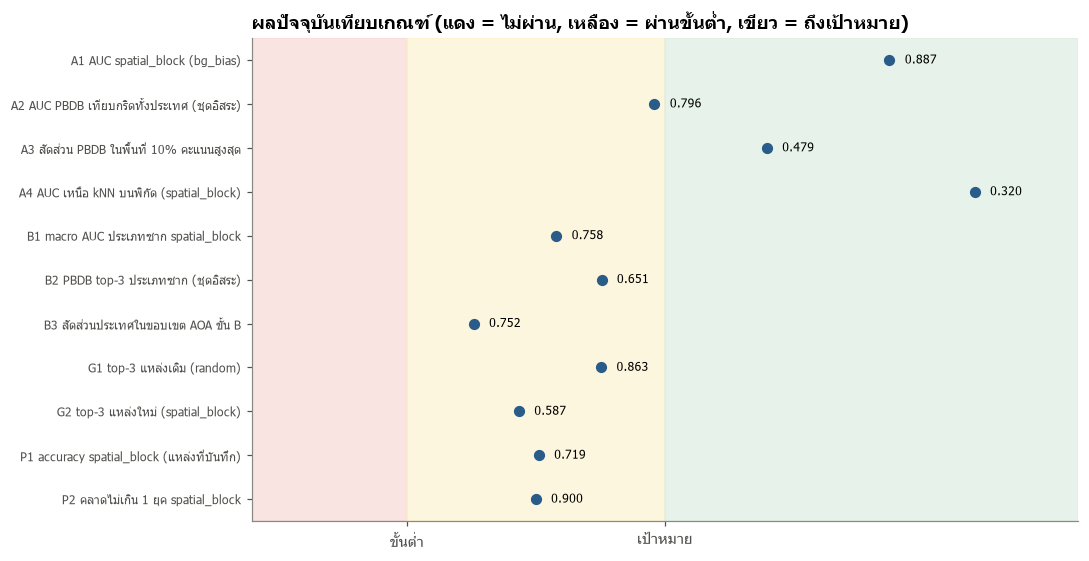

In [5]:
# ตำแหน่งของผลเทียบกับเกณฑ์: 0 = ขั้นต่ำ, 1 = เป้าหมาย (เฉพาะเกณฑ์ที่เป็นตัวเลขต่อเนื่อง)
num = CR[~CR["รหัส"].isin(["G3", "E1", "E2", "E3"])].iloc[::-1]          # ชื่อคอลัมน์ไทยใช้ [] เสมอ (attribute ถูก normalize สระอำ)
pos = (num["ผล"] - num["ขั้นต่ำ"]) / (num["เป้าหมาย"] - num["ขั้นต่ำ"])
fig, ax = plt.subplots(figsize=(10, 5.2))
ax.axvspan(-0.6, 0, color="#f6d3cf", alpha=0.6)
ax.axvspan(0, 1, color="#fdf0c8", alpha=0.6)
ax.axvspan(1, 2.6, color="#d7ecdc", alpha=0.6)
ax.scatter(pos.clip(-0.5, 2.5), range(len(num)), color="#2a5c8a", zorder=3, s=40)
for i, (p, v) in enumerate(zip(pos, num["ผล"])):
    ax.text(min(max(p, -0.5), 2.5) + 0.06, i, f"{v:.3f}", va="center", fontsize=8)
ax.set_yticks(range(len(num)), [f"{a} {b}" for a, b in zip(num["รหัส"], num["ตัวชี้วัด"])], fontsize=8)
ax.set_xticks([0, 1], ["ขั้นต่ำ", "เป้าหมาย"])
ax.set_xlim(-0.6, 2.6)
ax.set_title("ผลปัจจุบันเทียบเกณฑ์ (แดง = ไม่ผ่าน, เหลือง = ผ่านขั้นต่ำ, เขียว = ถึงเป้าหมาย)")
plt.tight_layout()

## 4. ข้อมูลประกอบ: ทายสกุลเมื่อผู้ใช้ไม่รู้ประเภทซาก (ไม่ใช่เกณฑ์ผ่าน / ไม่ผ่าน)

เว็บถาม "ซากหน้าตาเป็นอย่างไร" แทนประเภทซาก (notebook 15 หัวข้อ 7) — G1 / G2 วัดเมื่อรู้ประเภทและคำบรรยายครบตามทะเบียน
ตารางนี้บอกว่าความแม่นลดลงเท่าไรเมื่อข้อมูลน้อยลงทีละขั้น (top-3, out-of-fold ด้วยโมเดลของ fold เดิม) — ไม่นับเป็นเกณฑ์เพื่อไม่เลื่อนเส้นชัย
แบบบอกหน้าตานับตามที่เว็บแสดง: "ยังระบุชื่อไม่ได้" แยกเป็นรายการตามกลุ่มซาก และนับถูกเมื่อรายการของกลุ่มจริงอยู่ใน 3 อันดับ

In [6]:
LOOK = pd.read_parquet(ml.MODELS / "task1" / "FE" / "appearance_eval.parquet")
LOOK = LOOK[LOOK.deployed]
tLook = LOOK.pivot(index="scenario_th", columns="cv", values="top3").reindex(LOOK.drop_duplicates("scenario").scenario_th)
tLook.columns = [{"random": "แหล่งเดิม (เทียบ G1)", "spatial_block": "แหล่งใหม่ (เทียบ G2)"}[c] for c in tLook.columns]
assert np.isclose(tLook.iloc[0, 0], V["G1"]) and np.isclose(tLook.iloc[0, 1], V["G2"]), "แถวทะเบียนจริงต้องเท่า G1 / G2"
display(tLook.style.format("{:.3f}").background_gradient(cmap="Blues", axis=None))

,แหล่งเดิม (เทียบ G1),แหล่งใหม่ (เทียบ G2)
scenario_th,,
ทะเบียนจริง,0.863,0.587
ทะเบียนจริง · ไม่บอกที่พบ,0.662,0.536
รู้ประเภท ไม่มีชื่อเรียก,0.820,0.585
บอกหน้าตา ตอบคำถามต่อ,0.723,0.472
บอกหน้าตา แค่รูปแรก,0.586,0.374
รู้ประเภท ไม่มีชื่อเรียก · ไม่บอกที่พบ,0.587,0.530
บอกหน้าตา ตอบคำถามต่อ · ไม่บอกที่พบ,0.499,0.465
บอกหน้าตา แค่รูปแรก · ไม่บอกที่พบ,0.421,0.410
"เลือก ""ไม่ตรงกับแบบไหน""",0.304,0.154


## 5. ข้อมูลประกอบ: precision / recall / F1 ของทุกแบบจำลองที่เปรียบเทียบ (ไม่ใช่เกณฑ์ผ่าน / ไม่ผ่าน)

ตัวชี้วัดหลัก (AUC, accuracy, top-3) บอกภาพรวม แต่ไม่บอกว่าแบบจำลอง**พลาดแบบไหน** และ**ทำได้ดีกับคลาสที่พบน้อยหรือไม่** หัวข้อนี้วัดเพิ่ม
จาก**ผลทำนายนอก fold ชุดเดิม** ของทุกแบบจำลองในตารางเลือกแบบจำลอง (ไม่ train ใหม่)

- **precision** = ในบรรดาที่ทายว่าเป็นคลาสนั้น ถูกกี่ส่วน · **recall** = ในบรรดาที่เป็นคลาสนั้นจริง ทายเจอกี่ส่วน · **F1** = ค่าเฉลี่ยฮาร์มอนิกของสองค่า
- **macro** = เฉลี่ยทุกคลาสเท่ากัน (สกุล / ยุคที่พบน้อยมีน้ำหนักเท่าที่พบบ่อย) · **weighted** = ถ่วงตามจำนวนตัวอย่างของคลาส
- precision / recall / F1 **รวมผลทุก fold** แล้วคำนวณครั้งเดียว (fold แบบบล็อกพื้นที่มีขนาดไม่เท่ากัน ค่านี้จึงต่างจากค่าเฉลี่ยต่อ fold เล็กน้อย)
  ส่วน accuracy / AUC / top-3 ในตารางเป็น**ค่าเฉลี่ยต่อ fold** แบบเดียวกับ notebook ต้นทาง — ใช้ยืนยันว่าเป็นผลทำนายชุดเดียวกัน
- ขั้น A: จุดพื้นหลังไม่ใช่จุดที่ยืนยันว่าไม่มีซาก และจำนวนจุดพื้นหลังเป็นค่าที่ตั้งเอง precision จึงอ่านเป็นค่าเปรียบเทียบระหว่างแบบจำลองเท่านั้น;
  ใช้ PR-AUC และ F1 สูงสุด (เลือกเกณฑ์ที่ดีที่สุดของแต่ละแบบ) แทนเกณฑ์ 0.5 เพราะแต่ละแบบให้ความน่าจะเป็นคนละสเกล
- ขั้น B: แต่ละแหล่งมีได้หลายประเภท จึงนับ 3 อันดับแรกเป็นคำตอบ (precision@3 = ใน 3 ประเภทที่เสนอ มีจริงกี่ส่วน, recall@3 = ประเภทที่มีจริงอยู่ใน 3 อันดับกี่ส่วน)
- แถว "ระบบที่ใช้จริง" ของสกุล = สลับตามกรณี + ตัวกรองความสอดคล้อง แบบ notebook 15 หัวข้อ 5 (= G1 / G2)

In [7]:
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score
from sklearn.metrics import precision_recall_fscore_support as prfs


def fold_mean(o, f):
    return float(np.mean([f(g) for _, g in o.groupby("fold")]))


def mc_row(o, name, task):
    # o: oof หลายคลาส (fold, y, p_0..) -> accuracy / top-3 เฉลี่ยต่อ fold + P / R / F1 (macro, weighted) รวมทุก fold
    P = o[[c for c in o.columns if re.fullmatch(r"p_\d+", c)]].values
    o = o.assign(pred=P.argmax(axis=1), t3=[y in np.argsort(-p)[:3] for y, p in zip(o.y.values, P)])
    row = {"งาน": task, "แบบจำลอง": name, "accuracy": fold_mean(o, lambda g: (g.pred == g.y).mean()), "top-3": fold_mean(o, lambda g: g.t3.mean())}
    for avg in ["macro", "weighted"]:
        p, r, f, _ = prfs(o.y, o.pred, average=avg, zero_division=0)
        row.update({f"P {avg}": p, f"R {avg}": r, f"F1 {avg}": f})
    return row


# ---- ระบบสกุลที่ใช้จริง (สลับตามกรณี + ตัวกรอง) — สร้าง label / fold แบบเดียวกับ notebook 15
sites_ = allf[allf.source.eq("dmr_site")].merge(pd.read_parquet(ml.FEAT / "folds.parquet"), on="point_id")
sites_ = sites_.assign(site_OBJECTID=sites_.point_id.str[4:].astype(int).astype("Int64"))[["site_OBJECTID", "fold_site_cluster", "fold_spatial_block"]]
S = pd.read_csv(ml.DATA / "processed" / "fossil_list_final.csv", dtype={"fossil_id": str, "site_OBJECTID": "Int64"}, encoding="utf-8-sig", low_memory=False)
S["genus_true"] = S.sci_name.map(fl.parse_taxon).map(lambda t: t[0] if t else None)
S = S.merge(sites_, on="site_OBJECTID", how="left")
rng = np.random.default_rng(42)
S["fold_random"] = rng.integers(0, ml.N_FOLDS, len(S))
for sc in ["site_cluster", "spatial_block"]:
    S[f"fold_{sc}"] = S[f"fold_{sc}"].fillna(pd.Series(rng.integers(0, ml.N_FOLDS, len(S)), index=S.index)).astype(int)
COMV = set(S.loc[S.genus_true.isna(), "com_name"].dropna())
S["groups"] = [fl.specimen_classes(str(t), str(c if c in COMV else t)) for t, c in zip(S.f_type, S.com_name)]
labi = S[S.genus_true.notna()].set_index("fossil_id")
gcount = labi.genus_true.value_counts()
GENERA = sorted(gcount[gcount >= 5].index) + ["อื่น ๆ"]
assert GENERA == META1["genus"]["classes"], "รายชื่อสกุลไม่ตรงกับโมเดลตัวจริง"
labi["genus_cls"] = labi.genus_true.where(labi.genus_true.isin(GENERA), "อื่น ๆ")
regG, regG5 = ml.Registry(ml.MODELS / "task1" / "FE" / "genus_v2"), ml.Registry(ml.MODELS / "task1" / "genus_v5")
assert (regG5.oof("random__xgb").set_index("point_id").fold.reindex(labi.index) == labi.fold_random).all(), "fold ไม่ตรงกับ notebook 11"
PCOL = [f"p_{j}" for j in range(len(GENERA))]


def genus_system(cv, new_exp):
    a = regG.oof(f"known__{cv}__xgb@combo_known").set_index("point_id")
    b = regG.oof(f"new__{cv}__lgbm@{new_exp}").set_index("point_id").loc[a.index]
    parts = []
    for k in sorted(a.fold.unique()):
        ids = a.index[a.fold == k]
        tr = labi[labi[f"fold_{cv}"] != k]
        kn = ml.route_known_site(labi.loc[ids, "site_OBJECTID"], tr.site_OBJECTID.dropna().astype(int))
        P = ml.consistency_filter(np.where(kn[:, None], a.loc[ids, PCOL].values, b.loc[ids, PCOL].values),
                                  GENERA, labi.loc[ids, "groups"], ml.genus_group_map(tr.genus_cls, tr.groups))
        parts.append(pd.DataFrame(P, columns=PCOL).assign(fold=k, y=a.loc[ids, "y"].values))
    return pd.concat(parts, ignore_index=True)


SYS = {cv: genus_system(cv, "combo_new") for cv in ["random", "spatial_block"]}
for cv, cid in [("random", "G1"), ("spatial_block", "G2")]:
    assert np.isclose(fold_mean(SYS[cv], lambda g: np.mean([y in np.argsort(-p)[:3] for y, p in zip(g.y, g[PCOL].values)])), V[cid]), cid

# ---- งานที่ 1: สกุล (แหล่งเดิม = random, แหล่งใหม่ = spatial_block) และยุค (spatial_block, แหล่งที่ ทธ. บันทึกยุค)
GN = {"xgb": "XGBoost + คุณลักษณะแหล่ง", "lgbm": "LightGBM + คุณลักษณะแหล่ง", "lgbm@specimen": "LightGBM ข้อมูลตัวอย่างอย่างเดียว",
      "mlp": "MLP", "rf": "Random Forest", "knn_coords": "kNN บนพิกัด"}
rows1 = []
for cv, task in [("random", "สกุล แหล่งเดิม"), ("spatial_block", "สกุล แหล่งใหม่")]:
    rows1.append(mc_row(SYS[cv], "ระบบที่ใช้จริง", task))
    rows1 += [mc_row(regG5.oof(f"{cv}__{e}"), n, task) for e, n in GN.items()]
PN = {"lgbm@site+surface": "LightGBM + ผิวดิน (ใช้จริง)", "lgbm": "LightGBM", "rf": "Random Forest", "xgb": "XGBoost", "mlp": "MLP", "knn_coords": "kNN บนพิกัด"}
rows1 += [mc_row(regP.oof(f"spatial_block__{e}").pipe(lambda o: o[o.point_id.isin(recorded)]), n, "ยุคของแหล่ง") for e, n in PN.items()]
PRF1 = pd.DataFrame(rows1)
assert np.isclose(PRF1.loc[PRF1["แบบจำลอง"].eq("LightGBM + ผิวดิน (ใช้จริง)"), "accuracy"].iat[0], V["P1"])

# ---- งานที่ 2 ขั้น A (บล็อกพื้นที่, 2 ชุดพื้นหลัง)
AN = {"xgb": "XGBoost (ใช้จริง)", "lgbm": "LightGBM", "fusion": "LightGBM + CNN", "rf": "Random Forest", "mlp": "MLP", "cnn": "CNN",
      "knn": "kNN", "knn_coords": "kNN บนพิกัด"}
rowsA = []
for bgk in ["bg_bias", "bg_uniform"]:
    reg = ml.Registry(ml.MODELS / "task2" / f"A_{bgk}")
    for e, n in AN.items():
        o = reg.oof(f"spatial_block__{e}")
        pc, rc, _ = precision_recall_curve(o.y, o.p)
        f1 = 2 * pc * rc / np.maximum(pc + rc, 1e-12)
        i = int(np.nanargmax(f1))
        rowsA.append({"พื้นหลัง": bgk, "แบบจำลอง": n, "AUC": cv_mean(f"task2/A_{bgk}", f"spatial_block__{e}", "auc"),
                      "PR-AUC": average_precision_score(o.y, o.p), "F1 สูงสุด": f1[i], "P ที่ F1 สูงสุด": pc[i], "R ที่ F1 สูงสุด": rc[i],
                      "สัดส่วนจุดบวก": o.y.mean()})
PRFA = pd.DataFrame(rowsA)
# recall ของแหล่งทดสอบในพื้นที่ 10% คะแนนสูงสุดของประเทศ (แบบจำลองที่ใช้จริง, ผลนอก fold)
TOP10 = {}
for bgk in ["bg_bias", "bg_uniform"]:
    o = ml.Registry(ml.MODELS / "task2" / f"A_{bgk}").oof("spatial_block__xgb")
    TOP10[bgk] = float(np.mean(o.p[o.y == 1] >= np.quantile(grid[f"potential_{bgk}"], 0.9)))

# ---- งานที่ 2 ขั้น B (บล็อกพื้นที่, หลายป้าย) -> 3 อันดับแรกเป็นคำตอบ
BN = {"rf": "Random Forest (ใช้จริง)", "lgbm": "LightGBM", "fusion": "LightGBM + CNN", "xgb": "XGBoost", "mlp": "MLP",
      "knn_coords": "kNN บนพิกัด", "cnn": "CNN"}
regB = ml.Registry(ml.MODELS / "task2" / "B_v3")
rowsB = []
for e, n in BN.items():
    o = regB.oof(f"spatial_block__{e}")
    Y = o[[f"y_{j}" for j in range(len(KEEP))]].values.astype(int)
    P = o[[f"p_{j}" for j in range(len(KEEP))]].values
    has = Y.sum(axis=1) > 0
    hit = np.take_along_axis(Y[has], np.argsort(-P[has], axis=1)[:, :3], axis=1)
    p5, r5, f5, _ = prfs(Y[has], (P[has] >= 0.5).astype(int), average="micro", zero_division=0)
    rowsB.append({"แบบจำลอง": n, "top-3": cv_mean("task2/B_v3", f"spatial_block__{e}", "top3"), "precision@3": hit.mean(),
                  "recall@3": float(np.mean(hit.sum(axis=1) / Y[has].sum(axis=1))), "P @0.5": p5, "R @0.5": r5, "F1 @0.5": f5})
PRFB = pd.DataFrame(rowsB)
assert np.isclose(PRFB["top-3"].iat[0], cv_mean("task2/B_v3", "spatial_block__rf", "top3"))

# ---- NN ที่ใช้เป็นตัวสร้างคุณลักษณะ: ข้อความ (เส้นทางแหล่งใหม่ วัดเป็นระบบ) และเวกเตอร์ภาพ CNN
rowsN = [mc_row(genus_system("spatial_block", e), n, "ข้อความ (สกุล แหล่งใหม่ ทั้งระบบ)") for e, n in
         [("combo_new", "หมวดหิน + WangchanBERTa (ใช้จริง)"), ("combo_new_mlm", "หมวดหิน + multilingual MiniLM"), ("combo_new_fm", "หมวดหินอย่างเดียว")]]
for cv, task in [("random", "เวกเตอร์ CNN (สกุล แหล่งเดิม)"), ("spatial_block", "เวกเตอร์ CNN (สกุล แหล่งใหม่)")]:
    rowsN += [mc_row(regG5.oof(f"{cv}__{e}"), n, task) for e, n in
              [("lgbm@specimen+site", "LightGBM ตัวอย่าง + แหล่ง"), ("lgbm@specimen+site+cnn", "LightGBM ตัวอย่าง + แหล่ง + CNN")]]
rowsN += [mc_row(regP.oof(f"spatial_block__{e}").pipe(lambda o: o[o.point_id.isin(recorded)]), n, "เวกเตอร์ CNN (ยุค)") for e, n in
          [("lgbm", "LightGBM คุณลักษณะแหล่ง"), ("lgbm@site+cnn", "LightGBM + CNN"), ("lgbm@site+surface", "LightGBM + ผิวดิน (ใช้จริง)")]]
PRFN = pd.DataFrame(rowsN)

pd.concat([PRF1.assign(ตาราง="งาน 1"), PRFA.assign(ตาราง="ขั้น A"), PRFB.assign(ตาราง="ขั้น B"), PRFN.assign(ตาราง="NN สร้างคุณลักษณะ")]) \
  .to_csv(ml.MODELS / "model_prf.csv", index=False, encoding="utf-8-sig")
fmt = lambda d: d.style.format({c: "{:.3f}" for c in d.columns if d[c].dtype.kind == "f"}).hide(axis="index")
display(fmt(PRF1)), display(fmt(PRFA)), display(fmt(PRFB)), display(fmt(PRFN))
print("ขั้น A: แหล่งทดสอบในพื้นที่ 10% คะแนนสูงสุดของประเทศ (ผลนอก fold, XGBoost)", {k: round(v, 3) for k, v in TOP10.items()})

งาน,แบบจำลอง,accuracy,top-3,P macro,R macro,F1 macro,P weighted,R weighted,F1 weighted
สกุล แหล่งเดิม,ระบบที่ใช้จริง,0.667,0.863,0.423,0.412,0.401,0.628,0.667,0.634
สกุล แหล่งเดิม,XGBoost + คุณลักษณะแหล่ง,0.661,0.852,0.371,0.367,0.355,0.604,0.662,0.618
สกุล แหล่งเดิม,LightGBM + คุณลักษณะแหล่ง,0.600,0.809,0.429,0.502,0.427,0.659,0.600,0.593
สกุล แหล่งเดิม,LightGBM ข้อมูลตัวอย่างอย่างเดียว,0.582,0.809,0.430,0.514,0.424,0.692,0.582,0.570
สกุล แหล่งเดิม,MLP,0.556,0.740,0.371,0.482,0.383,0.657,0.557,0.527
สกุล แหล่งเดิม,Random Forest,0.539,0.740,0.365,0.497,0.384,0.659,0.539,0.510
สกุล แหล่งเดิม,kNN บนพิกัด,0.430,0.591,0.193,0.223,0.187,0.388,0.430,0.389
สกุล แหล่งใหม่,ระบบที่ใช้จริง,0.396,0.587,0.115,0.146,0.118,0.337,0.382,0.348
สกุล แหล่งใหม่,XGBoost + คุณลักษณะแหล่ง,0.275,0.515,0.076,0.058,0.053,0.159,0.229,0.141
สกุล แหล่งใหม่,LightGBM + คุณลักษณะแหล่ง,0.266,0.426,0.120,0.122,0.098,0.184,0.220,0.170


พื้นหลัง,แบบจำลอง,AUC,PR-AUC,F1 สูงสุด,P ที่ F1 สูงสุด,R ที่ F1 สูงสุด,สัดส่วนจุดบวก
bg_bias,XGBoost (ใช้จริง),0.887,0.626,0.594,0.616,0.573,0.094
bg_bias,LightGBM,0.884,0.632,0.604,0.627,0.583,0.094
bg_bias,LightGBM + CNN,0.882,0.570,0.595,0.660,0.542,0.094
bg_bias,Random Forest,0.864,0.530,0.537,0.480,0.608,0.094
bg_bias,MLP,0.846,0.522,0.536,0.577,0.500,0.094
bg_bias,CNN,0.792,0.269,0.365,0.275,0.541,0.094
bg_bias,kNN,0.754,0.299,0.385,0.314,0.500,0.094
bg_bias,kNN บนพิกัด,0.566,0.130,0.200,0.133,0.407,0.094
bg_uniform,XGBoost (ใช้จริง),0.930,0.719,0.667,0.667,0.666,0.094
bg_uniform,LightGBM,0.928,0.729,0.680,0.699,0.662,0.094


แบบจำลอง,top-3,precision@3,recall@3,P @0.5,R @0.5,F1 @0.5
Random Forest (ใช้จริง),0.776,0.419,0.494,0.534,0.212,0.303
LightGBM,0.771,0.401,0.485,0.442,0.350,0.391
LightGBM + CNN,0.771,0.386,0.469,0.432,0.368,0.397
XGBoost,0.759,0.402,0.479,0.443,0.370,0.403
MLP,0.734,0.387,0.466,0.349,0.654,0.455
kNN บนพิกัด,0.733,0.395,0.473,0.428,0.265,0.327
CNN,0.458,0.205,0.265,0.219,0.522,0.309


งาน,แบบจำลอง,accuracy,top-3,P macro,R macro,F1 macro,P weighted,R weighted,F1 weighted
ข้อความ (สกุล แหล่งใหม่ ทั้งระบบ),หมวดหิน + WangchanBERTa (ใช้จริง),0.396,0.587,0.115,0.146,0.118,0.337,0.382,0.348
ข้อความ (สกุล แหล่งใหม่ ทั้งระบบ),หมวดหิน + multilingual MiniLM,0.391,0.576,0.119,0.149,0.121,0.341,0.379,0.348
ข้อความ (สกุล แหล่งใหม่ ทั้งระบบ),หมวดหินอย่างเดียว,0.412,0.566,0.131,0.185,0.141,0.353,0.397,0.361
เวกเตอร์ CNN (สกุล แหล่งเดิม),LightGBM ตัวอย่าง + แหล่ง,0.597,0.811,0.440,0.508,0.431,0.682,0.597,0.591
เวกเตอร์ CNN (สกุล แหล่งเดิม),LightGBM ตัวอย่าง + แหล่ง + CNN,0.600,0.811,0.439,0.507,0.429,0.681,0.600,0.591
เวกเตอร์ CNN (สกุล แหล่งใหม่),LightGBM ตัวอย่าง + แหล่ง,0.278,0.526,0.134,0.130,0.109,0.335,0.236,0.198
เวกเตอร์ CNN (สกุล แหล่งใหม่),LightGBM ตัวอย่าง + แหล่ง + CNN,0.269,0.431,0.114,0.124,0.101,0.183,0.224,0.174
เวกเตอร์ CNN (ยุค),LightGBM คุณลักษณะแหล่ง,0.704,0.829,0.398,0.409,0.399,0.755,0.765,0.756
เวกเตอร์ CNN (ยุค),LightGBM + CNN,0.697,0.840,0.425,0.441,0.428,0.745,0.759,0.747
เวกเตอร์ CNN (ยุค),LightGBM + ผิวดิน (ใช้จริง),0.719,0.832,0.488,0.512,0.491,0.762,0.777,0.764


ขั้น A: แหล่งทดสอบในพื้นที่ 10% คะแนนสูงสุดของประเทศ (ผลนอก fold, XGBoost) {'bg_bias': 0.757, 'bg_uniform': 0.782}


In [8]:
# ข้อสังเกตหลัก (ตัวเลขจากตารางด้านบน)
g = PRF1.set_index(["งาน", "แบบจำลอง"])
kx, kl = g.loc[("สกุล แหล่งเดิม", "XGBoost + คุณลักษณะแหล่ง")], g.loc[("สกุล แหล่งเดิม", "LightGBM + คุณลักษณะแหล่ง")]
print(f"สกุลแหล่งเดิม: XGBoost accuracy {kx['accuracy']:.3f} / F1 weighted {kx['F1 weighted']:.3f} สูงกว่า LightGBM ({kl['accuracy']:.3f} / {kl['F1 weighted']:.3f}) "
      f"แต่ F1 macro ต่ำกว่า ({kx['F1 macro']:.3f} vs {kl['F1 macro']:.3f}) -> XGBoost ทายสกุลที่พบบ่อยดี สกุลที่พบน้อยด้อยกว่า; "
      f"ระบบที่ใช้จริง F1 macro {g.loc[('สกุล แหล่งเดิม', 'ระบบที่ใช้จริง'), 'F1 macro']:.3f}")
n = PRFN.set_index("แบบจำลอง")
print("ข้อความแหล่งใหม่ (accuracy / top-3 / F1 macro):",
      {k: tuple(round(n.loc[k, c], 3) for c in ["accuracy", "top-3", "F1 macro"]) for k in
       ["หมวดหิน + WangchanBERTa (ใช้จริง)", "หมวดหิน + multilingual MiniLM", "หมวดหินอย่างเดียว"]})

สกุลแหล่งเดิม: XGBoost accuracy 0.661 / F1 weighted 0.618 สูงกว่า LightGBM (0.600 / 0.593) แต่ F1 macro ต่ำกว่า (0.355 vs 0.427) -> XGBoost ทายสกุลที่พบบ่อยดี สกุลที่พบน้อยด้อยกว่า; ระบบที่ใช้จริง F1 macro 0.401
ข้อความแหล่งใหม่ (accuracy / top-3 / F1 macro): {'หมวดหิน + WangchanBERTa (ใช้จริง)': (np.float64(0.396), np.float64(0.587), np.float64(0.118)), 'หมวดหิน + multilingual MiniLM': (np.float64(0.391), np.float64(0.576), np.float64(0.121)), 'หมวดหินอย่างเดียว': (np.float64(0.412), np.float64(0.566), np.float64(0.141))}


**อ่านผล (ตรงกับตัวเลขของรอบรันล่าสุด)**
- ค่า **macro ต่ำกว่า weighted มากในทุกงาน** — แบบจำลองทำได้ดีกับสกุล / ยุคที่พบบ่อย แต่สกุล / ยุคที่มีตัวอย่างน้อยยังทายได้ไม่ดี
  (เหตุผลที่ระบบเสนอ 3 ชื่อและใช้ top-3 เป็นเกณฑ์)
- **สกุลแหล่งเดิม**: XGBoost ดีสุดด้าน accuracy และ weighted แต่ F1 macro ต่ำสุดในกลุ่มต้นไม้ — ข้อแลกเปลี่ยนที่ต้องระบุในรายงาน
- **สกุลแหล่งใหม่ / ยุค / ขั้น B**: แบบจำลองที่ใช้จริงดีที่สุดเกือบทุกค่า — ยืนยันการเลือก
- **ขั้น A**: XGBoost กับ LightGBM ต่างกันไม่เกิน 0.015 (น้อยกว่าความผันผวนระหว่าง fold ~0.03) — เสมอกันทางสถิติ; CNN ต่ำสุดทุกค่า
- **WangchanBERTa** ชนะเฉพาะ top-3 ส่วน accuracy / F1 แบบหมวดหินอย่างเดียวสูงกว่า (ต่างกันในระดับความผันผวน) — คง BERT ตามกติกาที่ตกลงไว้และเกณฑ์ G2 (top-3)
- **เวกเตอร์ CNN** ไม่ช่วยสกุล; ช่วย F1 macro ของยุคเล็กน้อยแต่ผิวดินดีกว่าทุกค่า

## สรุป

**ผ่านขั้นต่ำครบทุกข้อ** — ไม่มีข้อไหน "ไม่ผ่าน"

| สถานะ | เกณฑ์ |
|---|---|
| ถึงเป้าหมาย | A1 AUC ขั้น A 0.887 (≥ 0.80), A3 PBDB ในพื้นที่ 10% บนสุด 0.479 (≥ 0.40), A4 เหนือ kNN บนพิกัด 0.320 (≥ 0.20), G3 ทายข้ามกลุ่มซาก 0 ครั้ง, E1–E3 ด้านวิศวกรรม |
| ผ่านขั้นต่ำ แต่ยังไม่ถึงเป้าหมาย | A2 PBDB เทียบทั้งประเทศ 0.796 (เป้า 0.80 — ขาดนิดเดียว), B1 macro AUC ขั้น B 0.758, B2 PBDB top-3 0.651, B3 AOA ขั้น B 0.752, G1 สกุลแหล่งเดิม top-3 0.863, G2 สกุลแหล่งใหม่ top-3 0.587, P1 ยุค 0.719, P2 คลาดไม่เกิน 1 ยุค 0.900 |

**อ่านผล**
- **งานที่ 2 ขั้น A (โอกาสพบซาก) แข็งแรงที่สุด**: ถึงเป้าทุกข้อที่วัดใน CV และเกือบถึงเป้าในการตรวจกับทั้งประเทศ
- **ขั้น B (ประเภทซาก) และสกุลที่แหล่งใหม่** อยู่กลางระหว่างขั้นต่ำกับเป้าหมาย — ข้อจำกัดหลักคือ label (แหล่ง 490 แห่ง, การเชื่อมตัวอย่างระดับตำบล)
  และประเภทที่พบได้หลายยุค (หอยสองฝา, พืช, ร่องรอย)
- **ยุค**: ทายช่วงกว้างได้ดี (คลาดไม่เกิน 1 ยุค 0.900) แต่ทายยุคตรงยังห่างเป้า เพราะมีแหล่งที่บันทึกยุคแค่ 166 แหล่ง (เพอร์เมียน 88)
- สิ่งที่น่าจะดันเข้าเป้าได้มากที่สุดคือ**ข้อมูล** ไม่ใช่โมเดล: รหัสแหล่งในทะเบียนตัวอย่าง (แก้ label ขั้น B และสกุล) และยุคที่บันทึกเพิ่ม
  — การทดลอง feature ใน notebook 13–15 ได้ผลเพิ่มแค่ระดับ noise